# Vista RAW dei segnali + Start Index Cell (SIC) + correzione PADME

Script NUOVO e autonomo (non tocca `WC_analisys_tool.ipynb` ne' `RawView.ipynb`). Legge i
file `.mid.gz` reali con `wclib.py` (stessa libreria usata da WC_analisys_tool), calibra una
tabella di piedistallo per-capacitor (metodo PADME) e la applica ai segnali mostrati, con il
valore di **SIC** (Start Index Cell) sovrapposto a ogni evento (bank `DGH0`, campo gia'
estratto da `wc.daq_dgz_full2header`, valido per schede identificate come `1742` nel bank
MIDAS). Display e selezione eventi sono limitati alla finestra 100-250 ns.

**Cos'e' il SIC** (rif. PADME, Georgiev et al., *"Offline noise calibration of the CAEN
V1742 ADCs at the PADME experiment"*, J. Phys. Conf. Ser. 2255 (2022) 012008): il DRS4 e'
un buffer circolare di 1024 capacitor per canale; il SIC indica in quale capacitor fisico
e' stato scritto il campione 0 di QUESTO evento. La relazione tra il campione `t` (indice
nella waveform registrata) e la posizione fisica del capacitor `p` e':

```
p = (t + SIC) mod 1024
```

Eventi diversi hanno SIC diverso -> lo stesso capacitor fisico (con la sua eventuale
risposta anomala/piedistallo diverso) cade a un campione diverso in ogni evento. Questo e'
esattamente cio' che la correzione sotto sfrutta: si costruisce una tabella di piedistallo
per capacitor fisico (non per campione), e la si sottrae a ogni evento usando il suo SIC per
sapere quale valore di piedistallo usa ciascun campione.

In [12]:
%matplotlib inline
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

sys.path.insert(0, os.path.dirname(os.path.abspath(".")))
import wclib as wc

# ============================================================
# CONFIG
# ============================================================
RUN      = 1339
path     = '/Users/benussi/nmv-data/WC/WC26'                          # <- JupyterHub remoto
# path   = '/Users/benussi/Testbeam2026_WC_unified/Data_TB'           # <- locale
TAG      = ''
CLOUD    = False
VERBOSE  = False

# canali reali modulo singolo mod0 (vedi CLAUDE.md): ch_A=27, ch_B=26, ch_trig=17
CHANNELS = [27, 26, 17]
SIGNAL_CHANNELS = [27, 26]  # canali usati per decidere se l'evento "ha segnale" (solo PMT A/B, non trig)

N_EVENTS = 6                # quanti eventi CON SEGNALE mostrare (una figura ciascuno) — ignorato se EVENT_INDEX e' impostato
SHOW_CAPACITOR = True       # sovrappone p(t) = (t+SIC) mod 1024, in ns, su ogni segnale (asse Y secondario)
N_DROP_LAST_CELLS = 12      # scarta le ultime N celle temporali: spike noti, problema hardware V1742

SIG_THR_MV = -10.0          # soglia selezione: mostra solo eventi con segnale corretto <= soglia, su almeno uno dei SIGNAL_CHANNELS
MAX_SCAN   = 5000           # limite di sicurezza sul numero di eventi scansionati per trovare N_EVENTS con segnale
WINDOW_NS  = (50.0, 250.0)  # finestra segnale: stesso range di WC_analisys_tool.ipynb (DEBUG['wf_xlim_pmt_ns'])

# Se impostato, ignora la scansione/selezione e mostra SOLO l'evento con questo indice assoluto
# (1-based, un incremento per ogni evento con bank DGH0 dall'inizio del file — stessa convenzione
# di 'n_gen' in WC_analisys_tool.ipynb, cosi' i due script possono mostrare lo STESSO evento fisico
# impostando DEBUG['event_index'] = EVENT_INDEX in WC_analisys_tool.ipynb).
EVENT_INDEX = 1004          # es. 17 per l'evento assoluto #17; None = comportamento normale (scansione)

N_CALIB = 1000               # eventi usati per calibrare la tabella piedistallo E_p (metodo PADME)
N_VALID = 1000               # eventi successivi, disgiunti dalla calibrazione, usati per validare la correzione

ADC_BITS  = 12
V_PP_MV   = 1000.0
ADC_TO_MV = V_PP_MV / (2**ADC_BITS)
N_CELLS_DRS4 = 1024

mfile = wc.open_mid(run=RUN, path=path, cloud=CLOUD, tag=TAG, verbose=VERBOSE)
odb   = wc.get_bor_odb(mfile)
try:
    sf_mhz = float(odb.data['Configurations']['SamplingFrequency'])
    dt_ns  = 1000.0 / sf_mhz
except Exception:
    dt_ns = 0.4
print(f"Run {RUN} | dt_ns={dt_ns:.4f} ({1000.0/dt_ns:.0f} MS/s)")

/run01339.mid.gz
/run01339.mid.gz
[wclib] Calibrazione piedistallo PADME (per-capacitor): run 1339, 1000 eventi, 32 canali.
Run 1339 | dt_ns=0.4000 (2500 MS/s)


## Calibrazione piedistallo per-capacitor (metodo PADME)

Costruita PRIMA della vista eventi qui sotto, cosi' quest'ultima puo' mostrare la correzione
applicata a un singolo evento reale (non solo l'effetto medio su tante tracce come nella
sezione di validazione più in basso).

Per ogni canale si costruisce una tabella di piedistallo per-capacitor `E_p[cella]` (metodo
della **mediana**, robusto rispetto a impulsi reali occasionali, analogo al metodo "Mode" del
paper PADME — Georgiev et al. 2022), sui primi `N_CALIB` eventi. La correzione poi applicata e':

```
S_cor(t) = S_meas(t) - E_p[ (t + SIC) mod 1024 ]
```

In [13]:
import time

t0 = time.time()
mfile_calib = wc.open_mid(run=RUN, path=path, cloud=CLOUD, tag=TAG, verbose=VERBOSE)
cal_matrix = {ch: np.empty((N_CELLS_DRS4, N_CALIB), dtype=np.int16) for ch in CHANNELS}

n_ev = 0
for event in mfile_calib:
    if n_ev >= N_CALIB:
        break
    for bank_name, bank in event.banks.items():
        if 'DGH0' not in bank_name:
            continue
        header = wc.daq_dgz_full2header(bank, verbose=False)
        waveform = wc.daq_dgz_full2array(event.banks['DIG0'], header, verbose=False, pedestal_correction=False)
        n_ch = int(header.nchannels[0])
        n_sub = int(header.ntriggers[0])
        for isub in range(n_sub):
            if n_ev >= N_CALIB:
                break
            sic = int(header.SIC[0][isub])
            spc = len(waveform[isub * n_ch])
            cell_idx = (np.arange(spc) + sic) % N_CELLS_DRS4
            for ch in CHANNELS:
                wf = np.asarray(waveform[isub * n_ch + ch], dtype=np.int16)
                cal_matrix[ch][cell_idx, n_ev] = wf
            n_ev += 1
        break
print(f"Calibrazione E_p: {n_ev} eventi ({time.time()-t0:.1f}s)")

E_p = {ch: np.median(cal_matrix[ch], axis=1) for ch in CHANNELS}   # piedistallo per-capacitor, ADC counts
del cal_matrix

/run01339.mid.gz
/run01339.mid.gz
[wclib] Calibrazione piedistallo PADME (per-capacitor): run 1339, 1000 eventi, 32 canali.
Calibrazione E_p: 1000 eventi (23.0s)


## Vista eventi con correzione PADME applicata

Ogni campione viene corretto individualmente: `S_cor(t) = S_meas(t) - E_p[(t+SIC) mod 1024]`,
usando la tabella `E_p` appena costruita. Gli eventi usati per la calibrazione vengono saltati
(non mostrati qui), per non usare gli stessi eventi sia per calibrare sia per "abbellire" la
correzione mostrata.

/run01339.mid.gz
/run01339.mid.gz
[wclib] Calibrazione piedistallo PADME (per-capacitor): run 1339, 1000 eventi, 32 canali.


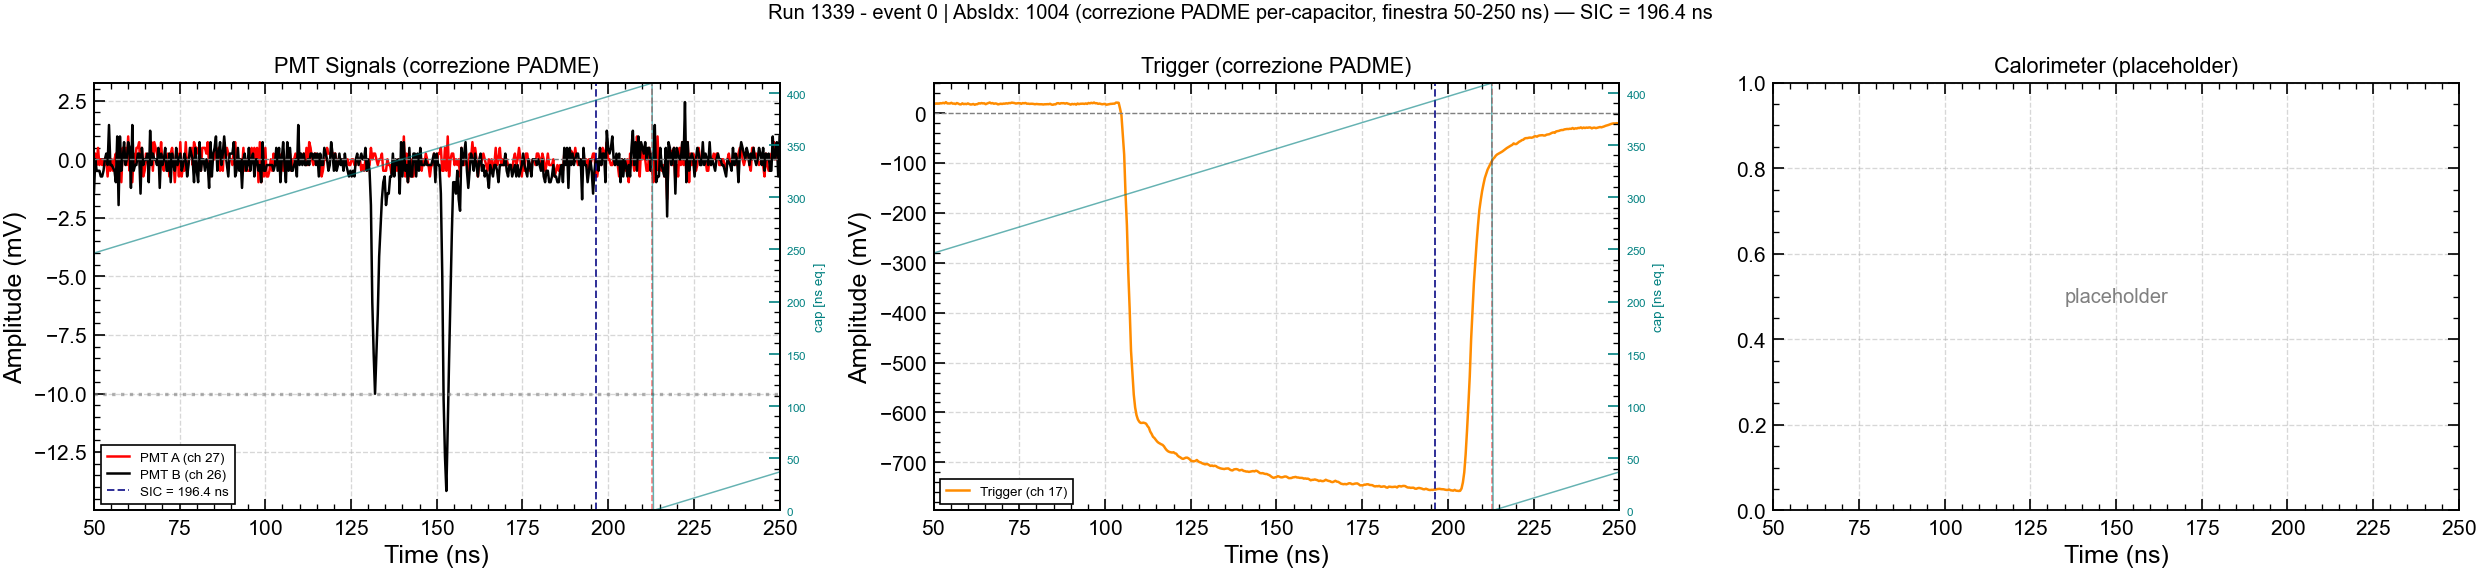


Mostrato evento assoluto #1004.


In [14]:
mfile_disp = wc.open_mid(run=RUN, path=path, cloud=CLOUD, tag=TAG, verbose=VERBOSE)

CH_A, CH_B, CH_TRIG = 27, 26, 17   # stessa mappatura di WC_analisys_tool.ipynb (mod0)

n_shown = 0
n_scanned = 0
n_skipped = 0
n_abs = 0   # indice assoluto evento (1-based), stessa convenzione di n_gen in WC_analisys_tool.ipynb

for event in mfile_disp:
    if n_shown >= N_EVENTS or n_scanned >= MAX_SCAN:
        break
    for bank_name, bank in event.banks.items():
        if 'DGH0' not in bank_name:
            continue
        header = wc.daq_dgz_full2header(bank, verbose=False)
        waveform = wc.daq_dgz_full2array(event.banks['DIG0'], header, verbose=False, pedestal_correction=False)

        n_ch  = int(header.nchannels[0])
        n_sub = int(header.ntriggers[0])          # sotto-eventi nello stesso blocco DGH0/DIG0
        spc_full = len(waveform[0])
        spc   = spc_full - N_DROP_LAST_CELLS       # celle finali scartate (spike noti V1742)
        t_ns  = np.arange(spc) * dt_ns
        full_window_ns = N_CELLS_DRS4 * dt_ns
        mask_win = (t_ns >= WINDOW_NS[0]) & (t_ns <= WINDOW_NS[1])

        for isub in range(n_sub):
            if n_shown >= N_EVENTS or n_scanned >= MAX_SCAN:
                break

            n_abs += 1

            if EVENT_INDEX is None:
                if n_skipped < N_CALIB:      # salta gli eventi usati per calibrare E_p (nessuna sovrapposizione)
                    n_skipped += 1
                    continue
                n_scanned += 1
            elif n_abs != EVENT_INDEX:
                continue

            sic = int(header.SIC[0][isub]) if len(header.SIC) > 0 else None
            sic_t_ns = sic * dt_ns if sic is not None else None
            cell_idx = (np.arange(spc) + sic) % N_CELLS_DRS4 if sic is not None else None
            p_ns = cell_idx * dt_ns if cell_idx is not None else None
            wrap_idx = np.where(np.diff(p_ns) < 0)[0] if p_ns is not None else []

            # --- correzione PADME per-capacitor: S_cor(t) = S_meas(t) - E_p[cella] ---
            wf_corr_by_ch = {}
            has_signal = False
            for ch in CHANNELS:
                wf_adc = np.asarray(waveform[isub * n_ch + ch][:spc], dtype=float)
                wf_corr = (wf_adc - E_p[ch][cell_idx]) * ADC_TO_MV
                wf_corr_by_ch[ch] = wf_corr
                if ch in SIGNAL_CHANNELS:
                    if wf_corr[mask_win].min() <= SIG_THR_MV:
                        has_signal = True

            # in modalita' scansione (EVENT_INDEX=None) si mostra solo se ha segnale;
            # in modalita' indice assoluto si mostra SEMPRE l'evento richiesto
            if EVENT_INDEX is None and not has_signal:
                continue

            # --- layout a 3 pannelli, stile WC_analisys_tool.ipynb ---
            fig, axes = plt.subplots(1, 3, figsize=(21, 5))

            # Pannello 1: PMT Signals (A+B sovrapposti, rosso/nero, come in WC_analisys_tool)
            ax0 = axes[0]
            ax0.plot(t_ns[mask_win], wf_corr_by_ch[CH_A][mask_win], color='red',   lw=1.5, label=f'PMT A (ch {CH_A})')
            ax0.plot(t_ns[mask_win], wf_corr_by_ch[CH_B][mask_win], color='black', lw=1.5, label=f'PMT B (ch {CH_B})')
            ax0.axhline(SIG_THR_MV, color='gray', ls=':', alpha=0.6)
            ax0.axhline(0, color='gray', lw=0.8, ls='--')
            if sic_t_ns is not None and WINDOW_NS[0] <= sic_t_ns <= WINDOW_NS[1]:
                ax0.axvline(sic_t_ns, color='navy', ls='--', lw=1.2, alpha=0.8, label=f'SIC = {sic_t_ns:.1f} ns')
            for wi in wrap_idx:
                if WINDOW_NS[0] <= t_ns[wi] <= WINDOW_NS[1]:
                    ax0.axvline(t_ns[wi], color='red', ls='--', lw=1.0, alpha=0.5)
            if SHOW_CAPACITOR and p_ns is not None:
                ax0_cap = ax0.twinx()
                ax0_cap.plot(t_ns[mask_win], p_ns[mask_win], lw=0.9, color='teal', alpha=0.6)
                ax0_cap.set_ylim(0, full_window_ns)
                ax0_cap.tick_params(axis='y', labelsize=7, colors='teal')
                ax0_cap.set_ylabel("cap [ns eq.]", fontsize=8, color='teal')
            ax0.set_title("PMT Signals (correzione PADME)")
            ax0.set_xlabel("Time (ns)"); ax0.set_ylabel("Amplitude (mV)")
            ax0.set_xlim(*WINDOW_NS)
            ax0.grid(True, ls='--', alpha=0.5); ax0.legend(loc='best', fontsize=8)

            # Pannello 2: Trigger
            ax1 = axes[1]
            ax1.plot(t_ns[mask_win], wf_corr_by_ch[CH_TRIG][mask_win], color='darkorange', lw=1.5,
                     label=f'Trigger (ch {CH_TRIG})')
            ax1.axhline(0, color='gray', lw=0.8, ls='--')
            if sic_t_ns is not None and WINDOW_NS[0] <= sic_t_ns <= WINDOW_NS[1]:
                ax1.axvline(sic_t_ns, color='navy', ls='--', lw=1.2, alpha=0.8)
            for wi in wrap_idx:
                if WINDOW_NS[0] <= t_ns[wi] <= WINDOW_NS[1]:
                    ax1.axvline(t_ns[wi], color='red', ls='--', lw=1.0, alpha=0.5)
            if SHOW_CAPACITOR and p_ns is not None:
                ax1_cap = ax1.twinx()
                ax1_cap.plot(t_ns[mask_win], p_ns[mask_win], lw=0.9, color='teal', alpha=0.6)
                ax1_cap.set_ylim(0, full_window_ns)
                ax1_cap.tick_params(axis='y', labelsize=7, colors='teal')
                ax1_cap.set_ylabel("cap [ns eq.]", fontsize=8, color='teal')
            ax1.set_title("Trigger (correzione PADME)")
            ax1.set_xlabel("Time (ns)"); ax1.set_ylabel("Amplitude (mV)")
            ax1.set_xlim(*WINDOW_NS)
            ax1.grid(True, ls='--', alpha=0.5); ax1.legend(loc='best', fontsize=8)

            # Pannello 3: placeholder (al posto del calorimetro, non serve per questo confronto)
            ax2 = axes[2]
            ax2.set_xlim(*WINDOW_NS)
            ax2.set_title("Calorimeter (placeholder)")
            ax2.set_xlabel("Time (ns)")
            ax2.text(0.5, 0.5, "placeholder", transform=ax2.transAxes,
                     ha='center', va='center', fontsize=12, color='gray')
            ax2.grid(True, ls='--', alpha=0.5)

            fig.suptitle(f"Run {RUN} - event {n_shown} | AbsIdx: {n_abs} (correzione PADME per-capacitor, finestra "
                         f"{WINDOW_NS[0]:.0f}-{WINDOW_NS[1]:.0f} ns) — SIC = {sic_t_ns:.1f} ns",
                         fontsize=12)
            plt.tight_layout()
            plt.show()
            plt.close(fig)

            n_shown += 1
            if EVENT_INDEX is not None:
                break
        if EVENT_INDEX is not None and n_shown > 0:
            break
        break   # una sola bank DGH0 per evento MIDAS
    if EVENT_INDEX is not None and n_shown > 0:
        break

if EVENT_INDEX is not None:
    if n_shown == 0:
        print(f"\nATTENZIONE: evento assoluto #{EVENT_INDEX} non trovato (il file ha solo {n_abs} eventi con bank DGH0).")
    else:
        print(f"\nMostrato evento assoluto #{EVENT_INDEX}.")
else:
    if n_shown < N_EVENTS:
        print(f"\nATTENZIONE: trovati solo {n_shown}/{N_EVENTS} eventi con segnale dopo aver scansionato {n_scanned} eventi (MAX_SCAN={MAX_SCAN}).")
    print(f"\nSaltati {n_skipped} eventi di calibrazione, scansionati {n_scanned}, mostrati {n_shown} eventi con segnale "
          f"(soglia {SIG_THR_MV} mV dopo correzione PADME, finestra {WINDOW_NS} ns, canali {SIGNAL_CHANNELS}).")

## Validazione della correzione (statistica su molti eventi)

Riusa la tabella `E_p` costruita sopra (primi `N_CALIB` eventi) e la applica a `N_VALID`
eventi successivi, **mai usati nella calibrazione**, per verificare se lo spread per-capacitor
si riduce davvero su dati indipendenti (altrimenti il confronto sarebbe drogato dall'aver
ottimizzato la correzione sugli stessi dati su cui la si misura).

In [15]:
mfile_valid = wc.open_mid(run=RUN, path=path, cloud=CLOUD, tag=TAG, verbose=VERBOSE)

# ---- VALIDAZIONE su N_VALID eventi successivi ai N_CALIB usati per costruire E_p sopra ----
sum_raw  = {ch: np.zeros(N_CELLS_DRS4) for ch in CHANNELS}
sum_corr = {ch: np.zeros(N_CELLS_DRS4) for ch in CHANNELS}
cnt      = {ch: np.zeros(N_CELLS_DRS4) for ch in CHANNELS}

n_ev = 0
n_skipped = 0
for event in mfile_valid:
    if n_ev >= N_VALID:
        break
    for bank_name, bank in event.banks.items():
        if 'DGH0' not in bank_name:
            continue
        header = wc.daq_dgz_full2header(bank, verbose=False)
        waveform = wc.daq_dgz_full2array(event.banks['DIG0'], header, verbose=False, pedestal_correction=False)
        n_ch = int(header.nchannels[0])
        n_sub = int(header.ntriggers[0])
        for isub in range(n_sub):
            if n_ev >= N_VALID:
                break
            if n_skipped < N_CALIB:      # salta gli eventi gia' usati per costruire E_p
                n_skipped += 1
                continue
            sic = int(header.SIC[0][isub])
            spc = len(waveform[isub * n_ch])
            cell_idx = (np.arange(spc) + sic) % N_CELLS_DRS4
            for ch in CHANNELS:
                wf = np.asarray(waveform[isub * n_ch + ch], dtype=float)
                vals_by_cell = np.empty(N_CELLS_DRS4)
                vals_by_cell[cell_idx] = wf
                sum_raw[ch]  += vals_by_cell
                sum_corr[ch] += vals_by_cell - E_p[ch]
                cnt[ch]      += 1
            n_ev += 1
        break
print(f"Validazione: {n_ev} eventi indipendenti dalla calibrazione (dopo {n_skipped} eventi di calibrazione saltati)\n")

mean_raw_mv, mean_corr_mv = {}, {}
print(f"{'ch':<4}{'spread RAW (mV)':<18}{'std RAW (mV)':<16}{'spread CORR (mV)':<20}{'std CORR (mV)':<16}{'riduzione std':<12}")
for ch in CHANNELS:
    mean_raw_mv[ch]  = (sum_raw[ch] / cnt[ch]) * ADC_TO_MV
    mean_corr_mv[ch] = (sum_corr[ch] / cnt[ch]) * ADC_TO_MV
    spread_raw, std_raw   = mean_raw_mv[ch].max() - mean_raw_mv[ch].min(), mean_raw_mv[ch].std()
    spread_corr, std_corr = mean_corr_mv[ch].max() - mean_corr_mv[ch].min(), mean_corr_mv[ch].std()
    riduz = std_raw / std_corr if std_corr > 0 else float('nan')
    print(f"{ch:<4}{spread_raw:<18.2f}{std_raw:<16.3f}{spread_corr:<20.2f}{std_corr:<16.3f}{riduz:<12.1f}x")

/run01339.mid.gz
/run01339.mid.gz
[wclib] Calibrazione piedistallo PADME (per-capacitor): run 1339, 1000 eventi, 32 canali.
Validazione: 1000 eventi indipendenti dalla calibrazione (dopo 1000 eventi di calibrazione saltati)

ch  spread RAW (mV)   std RAW (mV)    spread CORR (mV)    std CORR (mV)   riduzione std
27  4.26              0.558           0.98                0.128           4.4         x
26  4.87              0.850           1.86                0.200           4.3         x
17  53.18             12.882          50.82               12.363          1.0         x


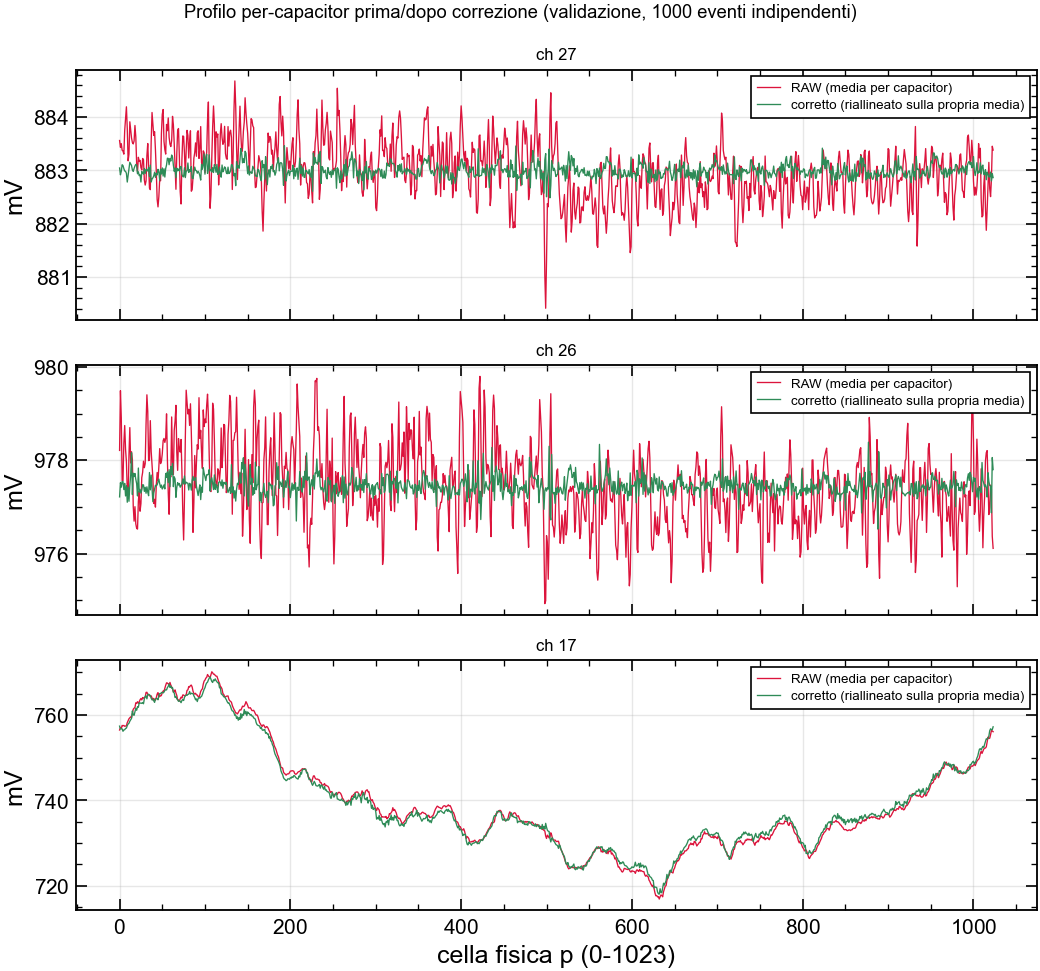

In [16]:
PLOT_CHANNELS = [27, 26, 17]   # ch A (grande recupero), ch B (grande recupero), ch trig (vero segnale, non migliora)

fig, axes = plt.subplots(len(PLOT_CHANNELS), 1, figsize=(9, 2.8 * len(PLOT_CHANNELS)), sharex=True)
for i, ch in enumerate(PLOT_CHANNELS):
    ax = axes[i]
    ax.plot(mean_raw_mv[ch], lw=0.8, color='crimson', label='RAW (media per capacitor)')
    # riallineo la curva corretta sulla PROPRIA media prima di sovrapporla: E_p e' basato sulla
    # mediana per-capacitor, mentre mean_raw_mv e' una media -> su canali con distribuzione
    # asimmetrica (es. ch17/trigger) mediana e media differiscono molto, e sommare semplicemente
    # mean_raw_mv[ch].mean() introdurrebbe un offset verticale spurio nel confronto visivo.
    corr_aligned = mean_corr_mv[ch] - mean_corr_mv[ch].mean() + mean_raw_mv[ch].mean()
    ax.plot(corr_aligned, lw=0.8, color='seagreen', label='corretto (riallineato sulla propria media)')
    ax.set_title(f"ch {ch}", fontsize=10)
    ax.set_ylabel("mV")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')
axes[-1].set_xlabel("cella fisica p (0-1023)")
fig.suptitle(f"Profilo per-capacitor prima/dopo correzione (validazione, {N_VALID} eventi indipendenti)",
             fontsize=11)
plt.tight_layout()
plt.show()